# **02 · Entrenamiento del modelo base**

Entrena el **modelo base** y hace una evaluación preliminar. Es el punto de partida contra el que se compara
la optimización de hiperparámetros del notebook 03.

- **Modelo:** YOLO26n (Ultralytics), una red de detección de objetos. En una sola pasada entrega, para cada
  limón, una caja y una confianza. La `n` (*nano*) es la versión más liviana: tiene que correr en la
  Raspberry Pi 5 del robot.
- **Transfer learning:** se parte de pesos preentrenados en COCO (80 clases de objetos comunes) y se ajusta
  a una sola clase nueva, `limon`.
- **Hiperparámetros:** los que trae Ultralytics por defecto, los mismos de la versión 3 del detector del
  grupo de Robótica.

> **Antes de empezar (Colab):** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*, y
> haber corrido el notebook 01. El entrenamiento tarda unos 15 minutos.

## **1. Preparación del entorno**

In [1]:
# Instalamos ultralytics (YOLO), en la misma versión que usa la Raspberry Pi del robot.
!pip -q install "ultralytics==8.4.153"

In [2]:
# Carpetas del proyecto. En Colab todo queda en Drive (carpeta limon_ia), con la misma estructura
# que el repositorio: data/, results/ y runs/ (modelos entrenados). Fuera de Colab se usa el repositorio.
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/limon_ia")   # carpeta del proyecto en Drive
    TRABAJO = Path("/content")                        # disco de Colab: rápido, pero se borra al cerrar
except ImportError:
    BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    TRABAJO = BASE / "data"

DATA, RESULTS, RUNS = BASE / "data", BASE / "results", BASE / "runs"
for carpeta in (DATA, RESULTS, RUNS):
    carpeta.mkdir(parents=True, exist_ok=True)
DATOS = TRABAJO / "datos"                             # dataset unificado, descomprimido
print("Proyecto en", BASE)

Mounted at /content/drive
Proyecto en /content/drive/MyDrive/limon_ia


In [3]:
import shutil
import random

import cv2
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from ultralytics import YOLO

IMGSZ = 640        # resolución a la que se redimensionan las imágenes
EPOCAS = 60        # máximo de pasadas completas por el dataset
PACIENCIA = 20     # parada temprana: corta si la validación no mejora en esta cantidad de épocas

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
# --------
# Función que deja listo el dataset para entrenar.
#   - Descomprime data/datos_limon.zip (lo genera el notebook 01) si todavía no está en el disco.
#   - Repite "repetir" veces las fotos propias de entrenamiento (sobremuestreo), para que pesen más
#     frente a las 915 imágenes del dataset base.
#   - Devuelve: la ruta del archivo .yaml que le dice a YOLO dónde están train y val.
# --------
def preparar_datos(repetir=3):
    if not (DATOS / "propio").exists():
        shutil.unpack_archive(DATA / "datos_limon.zip", DATOS)
    rep = DATOS / "propio" / f"train_x{repetir}"
    if not rep.exists():
        for sub in ("images", "labels"):
            (rep / sub).mkdir(parents=True)
        for img in sorted((DATOS / "propio" / "train" / "images").iterdir()):
            etiqueta = DATOS / "propio" / "train" / "labels" / (img.stem + ".txt")
            for k in range(repetir):
                shutil.copy(img, rep / "images" / f"r{k}_{img.name}")
                shutil.copy(etiqueta, rep / "labels" / f"r{k}_{img.stem}.txt")
    # train: todo el dataset base + las fotos propias de train repetidas. val: las 10 fotos propias de valid.
    train = [str(DATOS / "base" / s / "images") for s in ("train", "valid", "test")
             if any((DATOS / "base" / s / "images").glob("*"))] + [str(rep / "images")]
    ruta = TRABAJO / f"limones_x{repetir}.yaml"
    ruta.write_text(yaml.safe_dump({"train": train, "val": str(DATOS / "propio" / "valid" / "images"),
                                    "nc": 1, "names": {0: "limon"}}))
    return str(ruta)


# --------
# Función que evalúa un modelo sobre una o más carpetas de imágenes.
#   - Recibe: el modelo, un nombre para la fila y los conjuntos propios a usar ("valid", "test").
#   - Devuelve: diccionario con precisión, recobrado, F1, mAP50 y mAP50-95.
# --------
def evaluar(modelo, nombre, conjuntos):
    carpetas = [str(DATOS / "propio" / c / "images") for c in conjuntos]
    ruta = TRABAJO / f"eval_{'_'.join(conjuntos)}.yaml"
    ruta.write_text(yaml.safe_dump({"train": carpetas, "val": carpetas, "nc": 1, "names": {0: "limon"}}))
    m = modelo.val(data=str(ruta), imgsz=IMGSZ, project=str(TRABAJO / "evals"), name=nombre, exist_ok=True,
                   verbose=False, plots=False)
    p, r = float(m.box.mp), float(m.box.mr)
    return {"modelo": nombre, "conjunto": "+".join(conjuntos),
            "imágenes": sum(len(list(Path(c).glob("*"))) for c in carpetas),
            "precisión": round(p, 3), "recobrado": round(r, 3), "F1": round(2 * p * r / (p + r + 1e-9), 3),
            "mAP50": round(float(m.box.map50), 3), "mAP50-95": round(float(m.box.map), 3)}

## **2. Datos de entrenamiento**

Las 30 fotos propias de entrenamiento se repiten 3 veces (sobremuestreo): son pocas frente a las 915
imágenes del dataset base, y son las que más se parecen a lo que ve el robot.

In [5]:
yaml_datos = preparar_datos(repetir=3)
print(open(yaml_datos).read())

names:
  0: limon
nc: 1
train:
- /content/datos/base/train/images
- /content/datos/base/valid/images
- /content/datos/base/test/images
- /content/datos/propio/train_x3/images
val: /content/datos/propio/valid/images



## **3. Entrenamiento**

En cada época el modelo recorre todas las imágenes de entrenamiento, ajusta sus pesos y se evalúa con las 10
fotos propias de validación. Al final queda guardado `best.pt`, el modelo de la época con mejor validación.
Los resultados quedan en `runs/base/`: si esa carpeta ya tiene un `best.pt`, no se vuelve a entrenar.

In [6]:
mejor_base = RUNS / "base" / "weights" / "best.pt"
if mejor_base.exists():
    print("Ya hay un modelo base entrenado:", mejor_base)
else:
    modelo = YOLO("yolo26n.pt")            # pesos preentrenados en COCO (se descargan solos)
    modelo.train(
        data=yaml_datos,                   # dataset: base + fotos propias
        epochs=EPOCAS,                     # número máximo de épocas
        imgsz=IMGSZ,                       # tamaño de imagen
        batch=16,                          # imágenes por lote (bajar a 8 si falta memoria de GPU)
        patience=PACIENCIA,                # parada temprana
        seed=0,                            # semilla, para poder repetir el resultado
        project=str(RUNS), name="base",    # carpeta de resultados: runs/base
        exist_ok=True,
    )

# Copiamos a results/ la tabla con las pérdidas y métricas de cada época.
shutil.copy(RUNS / "base" / "results.csv", RESULTS / "base_curvas.csv")
print("Curvas guardadas en", RESULTS / "base_curvas.csv")

New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/limones_x3.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, m

## **4. Evaluación preliminar**

Métricas que se usan en todo el proyecto:

| Métrica | Qué mide |
|---|---|
| **Precisión (P)** | De las cajas que marca el modelo, qué fracción son limones. Si es baja, el brazo iría a buscar hojas |
| **Recobrado (R)** | De los limones que hay, qué fracción encuentra. Si es bajo, quedan limones sin cosechar |
| **F1** | Media armónica de P y R: un solo número que penaliza si alguna de las dos es baja |
| **mAP50** | Resume P y R para todos los umbrales de confianza. Una caja es correcta si se superpone al menos 50 % con la real |
| **mAP50-95** | Lo mismo, promediando exigencias de superposición de 50 a 95 %: mide qué tan ajustadas son las cajas. **Es la métrica que se optimiza en el notebook 03** |

Criterio de aceptación (requisito del robot): **P ≥ 0,80 y R ≥ 0,80**.

Esta evaluación se hace sobre las 10 fotos de **validación**. Las 10 de test no se tocan hasta el notebook 04.

In [7]:
modelo_base = YOLO(str(mejor_base))
fila = evaluar(modelo_base, "base", ["valid"])
metricas = pd.DataFrame([fila])
metricas.to_csv(RESULTS / "metricas_base.csv", index=False)
print("Criterio P y R >= 0,80:", "CUMPLE" if fila["precisión"] >= 0.8 and fila["recobrado"] >= 0.8 else "NO CUMPLE")
metricas

Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1819.8±239.0 MB/s, size: 78.8 KB)
val: Scanning /content/datos/propio/valid/labels.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 2.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 7.8it/s 0.1s
                   all         10         58          1      0.923      0.974      0.778
Speed: 0.4ms preprocess, 4.6ms inference, 0.0ms loss, 1.0ms postprocess per image
Criterio P y R >= 0,80: CUMPLE


,modelo,conjunto,imágenes,precisión,recobrado,F1,mAP50,mAP50-95
0,base,valid,10,1.0,0.923,0.96,0.974,0.778


### **4.1 Curvas de entrenamiento**

Las pérdidas (*loss*) deben bajar y las métricas, subir. Si la pérdida de validación sube mientras la de
entrenamiento baja, el modelo está sobreajustando (memoriza en lugar de generalizar). El análisis completo de
las curvas está en el notebook 04.

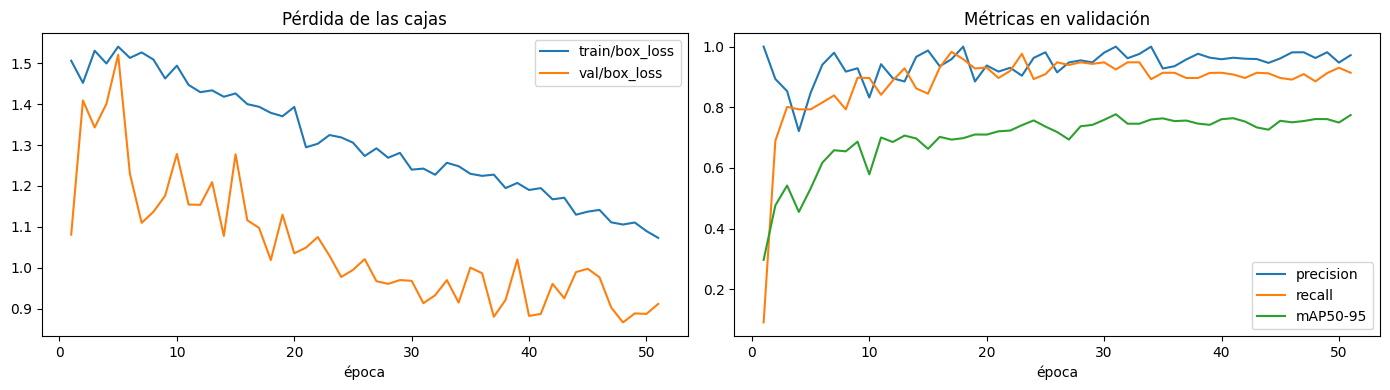

Épocas entrenadas: 51 de 60 | mejor época: 31


In [8]:
curvas = pd.read_csv(RUNS / "base" / "results.csv")
curvas.columns = curvas.columns.str.strip()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
for col in ("train/box_loss", "val/box_loss"):
    ax1.plot(curvas["epoch"], curvas[col], label=col)
ax1.set_title("Pérdida de las cajas"); ax1.set_xlabel("época"); ax1.legend()
for col in ("metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50-95(B)"):
    ax2.plot(curvas["epoch"], curvas[col], label=col.split("/")[1].replace("(B)", ""))
ax2.set_title("Métricas en validación"); ax2.set_xlabel("época"); ax2.legend()
plt.tight_layout()
plt.show()
print("Épocas entrenadas:", len(curvas), "de", EPOCAS,
      "| mejor época:", int(curvas.loc[curvas["metrics/mAP50-95(B)"].idxmax(), "epoch"]))

### **4.2 Primeras predicciones**

Tres fotos de validación con lo que detecta el modelo base. `CONF_MIN` es la confianza mínima para aceptar
una detección.

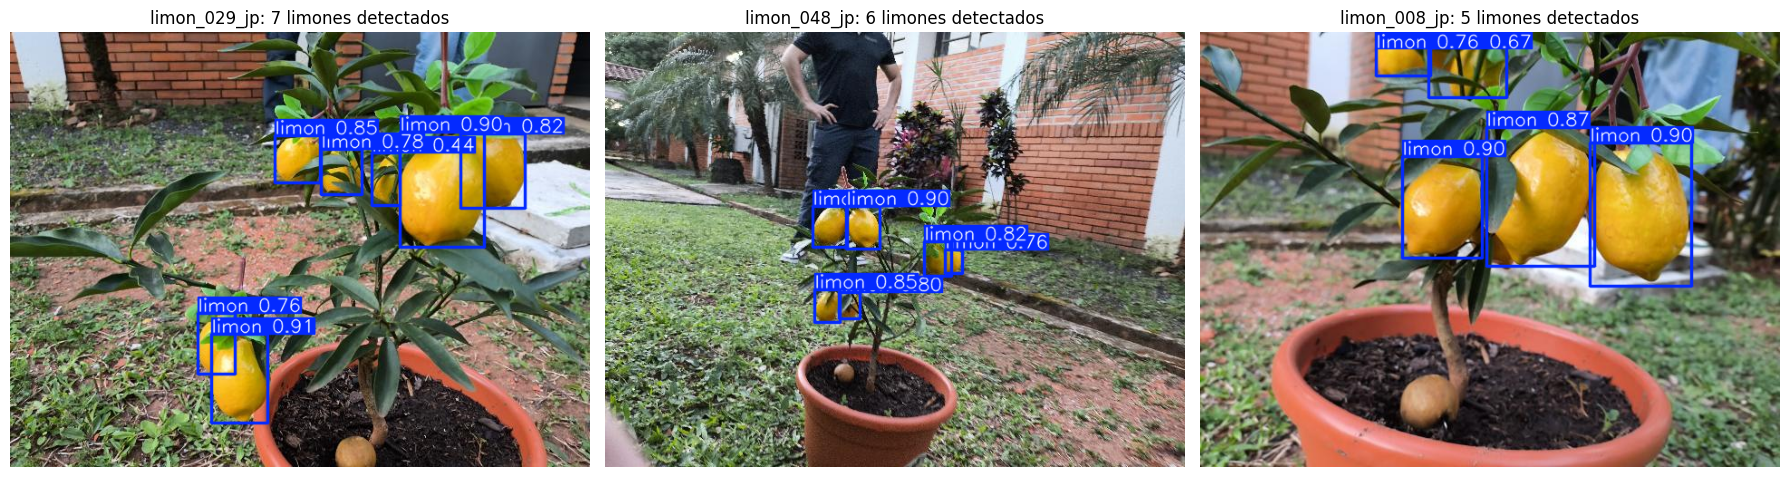

In [9]:
CONF_MIN = 0.40
fotos = random.Random(0).sample(sorted((DATOS / "propio" / "valid" / "images").iterdir()), 3)
plt.figure(figsize=(18, 7))
for i, foto in enumerate(fotos):
    r = modelo_base.predict(str(foto), conf=CONF_MIN, imgsz=IMGSZ, verbose=False)[0]
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    plt.title(f"{foto.name[:12]}: {len(r.boxes)} limones detectados")
    plt.axis("off")
plt.tight_layout()
plt.show()

**Análisis.** El modelo base, evaluado sobre las 20 fotos propias de validación y test (116 limones), dio P = 0,929, R = 0,922, mAP50 = 0,952 y mAP50-95 = 0,746. Son los mismos valores que la corrida del 12/11 del grupo de Robótica, y también coincide la época: el entrenamiento paró en la 51 y la mejor fue la 31 (paciencia de 20). Es decir, el notebook reproduce el resultado anterior.

Las curvas no muestran un sobreajuste marcado: la pérdida de entrenamiento baja de forma continua (1,51 a 1,07) y la de validación también, con altibajos (mínimo 0,87 en la época 48, 0,91 al final). El mAP50-95 de validación deja de mejorar después de la época 31 y por eso el entrenamiento se detiene 20 épocas después (paciencia). Con solo 10 fotos de validación las curvas son ruidosas. Se cumple el criterio de P y R ≥ 0,80.